<a href="https://colab.research.google.com/github/Aceeee-ux/Fundamentals-Of-AI-and-Data-Science-Project/blob/main/B00173571_AceJerickMagistrado_AI_DS_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Fundamental of AI and Data Science Cybersecurity Project

#### Dataset: `Dataset2_odd_students.csv`



---
## Step 0: Import Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

import warnings
warnings.filterwarnings('ignore')

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


---
## Step 1: Load the Dataset

In [ ]:
df = pd.read_csv('Dataset2_odd_students.csv')

print('─' * 50)
print(f'  Rows    : {df.shape[0]}')
print(f'  Columns : {df.shape[1]}')
print('─' * 50)
print('\nColumn names and types:')
print(df.dtypes)
print('\nFirst 5 rows:')
df.head()

──────────────────────────────────────────────────
  Rows    : 6000
  Columns : 19
──────────────────────────────────────────────────

Column names and types:
packet_session_id     object
protocol              object
device_type           object
vpn_status            object
region                object
login_attempts         int64
failed_logins          int64
bytes_sent           float64
bytes_received       float64
packet_rate          float64
connection_count       int64
tcp_flags             object
port_number            int64
session_retries        int64
signal_strength      float64
privilege_level       object
anomaly_score        float64
avg_packet_size      float64
attack_category       object
dtype: object

First 5 rows:


,packet_session_id,protocol,device_type,vpn_status,region,login_attempts,failed_logins,bytes_sent,bytes_received,packet_rate,connection_count,tcp_flags,port_number,session_retries,signal_strength,privilege_level,anomaly_score,avg_packet_size,attack_category
0,P000000,TCP,Workstation,On,APAC,0,6,3735.701997,7083.530344,184.514770,7,FIN,3389,0,-71.345111,user,0.117355,332.602010,Benign
1,P000001,TCP,Workstation,Off,EU,1,2,6140.866808,4382.336675,155.062604,5,ACK,110,1,-44.351883,user,0.238888,314.553416,Benign
2,P000002,TCP,Workstation,Off,US,3,0,4714.244672,6979.428832,125.959250,4,FIN,80,0,-64.475005,user,0.123961,266.942545,Benign
3,P000003,UDP,Server,Off,APAC,2,0,2987.854450,2715.307765,88.444309,3,FIN,110,1,-48.033202,guest,0.462781,259.362639,BruteForce
4,P000004,UDP,IoT,Off,US,1,5,5021.324823,4858.666310,153.385483,2,SYN-ACK,110,2,-65.320352,user,0.185527,293.294721,BruteForce


In [ ]:
print('Summary statistics — numeric columns:')
df.describe().round(2)

Summary statistics — numeric columns:


,login_attempts,failed_logins,bytes_sent,bytes_received,packet_rate,connection_count,port_number,session_retries,signal_strength,anomaly_score,avg_packet_size
count,6000.00,6000.00,6000.00,5580.00,6000.00,6000.00,6000.00,6000.00,5580.00,6000.00,6000.00
mean,1.99,1.01,5244.93,6030.81,125.41,5.01,464.33,0.99,-60.00,0.29,291.96
std,1.40,1.01,3148.81,2024.97,66.67,2.23,1022.54,0.99,9.96,0.16,23.27
min,0.00,0.00,100.00,100.00,10.00,0.00,21.00,0.00,-96.50,0.00,198.96
25%,1.00,0.00,3985.12,4698.08,99.43,3.00,25.00,0.00,-66.73,0.16,276.48
50%,2.00,1.00,4971.30,6036.93,120.36,5.00,80.00,1.00,-59.99,0.27,291.74
75%,3.00,2.00,6017.94,7403.42,140.34,6.00,143.00,2.00,-53.39,0.40,307.61
max,8.00,6.00,53602.25,14261.02,1068.62,16.00,3389.00,6.00,-25.85,0.85,375.36


In [ ]:
print('Missing values per column:')
missing = df.isnull().sum()
pct = (missing / len(df) * 100).round(1)
print(pd.DataFrame({'Count': missing, '%': pct}))

Missing values per column:
                   Count    %
packet_session_id      0  0.0
protocol             420  7.0
device_type            0  0.0
vpn_status             0  0.0
region                 0  0.0
login_attempts         0  0.0
failed_logins          0  0.0
bytes_sent             0  0.0
bytes_received       420  7.0
packet_rate            0  0.0
connection_count       0  0.0
tcp_flags              0  0.0
port_number            0  0.0
session_retries        0  0.0
signal_strength      420  7.0
privilege_level        0  0.0
anomaly_score          0  0.0
avg_packet_size        0  0.0
attack_category        0  0.0


---
## Step 2: Exploratory Data Analysis

Before building a model, I checked the class balance and some important patterns. This matters because an imbalanced dataset can make accuracy look better than the model really is.

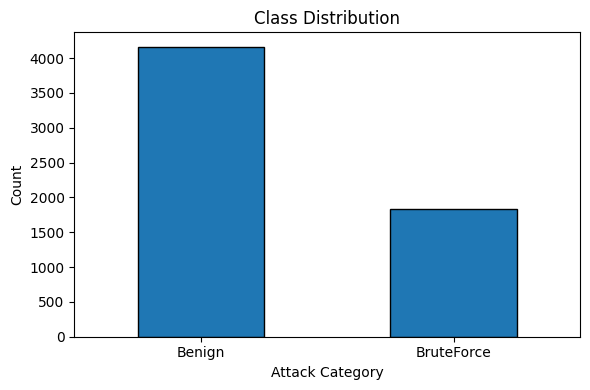

>> OBSERVATION: The dataset is imbalanced.
>> Benign has 4161 rows and BruteForce has 1839 rows.
>> Accuracy on its own can be misleading, so I also use F1 and recall.


In [ ]:
fig, ax = plt.subplots(figsize=(6, 4))
counts = df['attack_category'].value_counts()
counts.plot(kind='bar', ax=ax, edgecolor='black')
ax.set_title('Class Distribution')
ax.set_xlabel('Attack Category')
ax.set_ylabel('Count')
ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()


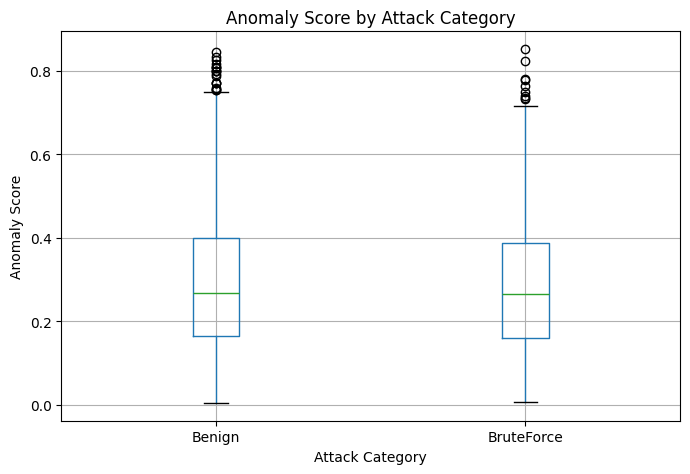

In [ ]:
fig, ax = plt.subplots(figsize=(7, 5))
df.boxplot(column='anomaly_score', by='attack_category', ax=ax)
ax.set_title('Anomaly Score by Attack Category')
ax.set_xlabel('Attack Category')
ax.set_ylabel('Anomaly Score')
plt.suptitle('')
plt.tight_layout()
plt.show()

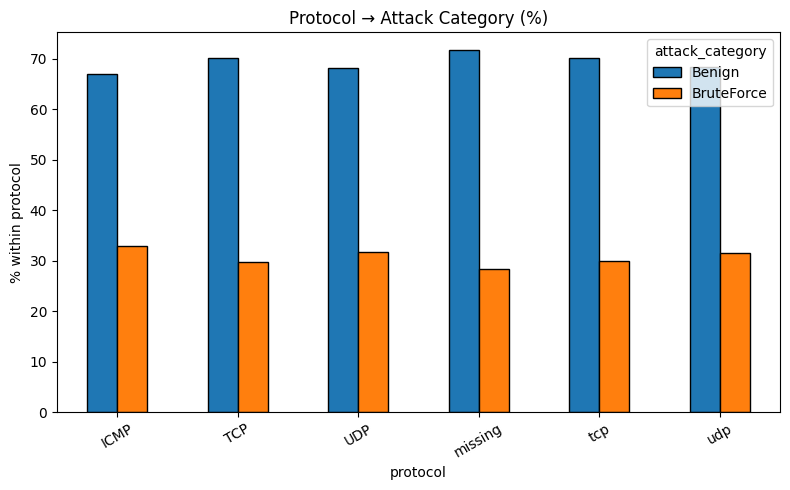

In [ ]:
ct = pd.crosstab(df['protocol'].fillna('missing'), df['attack_category'], normalize='index') * 100
ax = ct.plot(kind='bar', figsize=(8, 5), edgecolor='black')
ax.set_title('Protocol → Attack Category (%)')
ax.set_ylabel('% within protocol')
ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

---
## Step 3: Pre-processing

KNN needs clean numbers. It cannot calculate distance with missing values or raw text. This is why I fill missing values, encode categories, and scale the features.

In [ ]:
df_clean = df.copy()

id_col = 'packet_session_id'
target = 'attack_category'
cat_cols = [c for c in df_clean.select_dtypes(include='object').columns if c not in [id_col, target]]
num_cols = [c for c in df_clean.select_dtypes(exclude='object').columns]

# Fill numeric missing values with the median
for col in num_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

# Fill categorical missing values with the mode
for col in cat_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])

print('Missing values after cleaning:')
print(df_clean.isnull().sum())

Missing values after cleaning:
packet_session_id    0
protocol             0
device_type          0
vpn_status           0
region               0
login_attempts       0
failed_logins        0
bytes_sent           0
bytes_received       0
packet_rate          0
connection_count     0
tcp_flags            0
port_number          0
session_retries      0
signal_strength      0
privilege_level      0
anomaly_score        0
avg_packet_size      0
attack_category      0
dtype: int64


In [ ]:
# Encode categorical features using LabelEncoder, similar to the lab style
encoders = {}
for col in cat_cols:
    le = LabelEncoder()
    df_clean[col + '_enc'] = le.fit_transform(df_clean[col].astype(str))
    encoders[col] = le

# Target label
le_attack = LabelEncoder()
df_clean['label'] = le_attack.fit_transform(df_clean[target])

print('Target classes:', list(le_attack.classes_))
print('0/1 encoding:', dict(zip(le_attack.classes_, le_attack.transform(le_attack.classes_))))

Target classes: ['Benign', 'BruteForce']
0/1 encoding: {'Benign': np.int64(0), 'BruteForce': np.int64(1)}


In [ ]:
# Two features
# failure_rate: how much of the login activity failed
# traffic_total: overall traffic volume in the session

df_clean['failure_rate'] = df_clean['failed_logins'] / (df_clean['login_attempts'] + 1)
df_clean['traffic_total'] = df_clean['bytes_sent'] + df_clean['bytes_received']

FEATURES = num_cols + [c + '_enc' for c in cat_cols] + ['failure_rate', 'traffic_total']
X = df_clean[FEATURES]
y = df_clean['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f'Training rows : {len(X_train)}')
print(f'Test rows     : {len(X_test)}')

Training rows : 4800
Test rows     : 1200


In [ ]:
# Scale for KNN
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

before = pd.DataFrame(X_train, columns=FEATURES).describe().loc[['mean', 'std']].round(2)
after = pd.DataFrame(X_train_scaled, columns=FEATURES).describe().loc[['mean', 'std']].round(3)

print('BEFORE scaling:')
print(before)
print('\nAFTER scaling:')
print(after)

BEFORE scaling:
      login_attempts  failed_logins  bytes_sent  bytes_received  packet_rate  \
mean            1.99           1.00     5265.00         6046.12       125.35   
std             1.41           1.01     3280.55         1965.26        67.64   

      connection_count  port_number  session_retries  signal_strength  \
mean              5.01       473.12             0.98           -59.99   
std               2.24      1036.68             0.98             9.56   

      anomaly_score  avg_packet_size  protocol_enc  device_type_enc  \
mean           0.29           292.04          1.60             1.51   
std            0.16            23.27          1.08             1.12   

      vpn_status_enc  region_enc  tcp_flags_enc  privilege_level_enc  \
mean            0.30        1.50           1.50                 1.53   
std             0.46        1.11           1.13                 0.79   

      failure_rate  traffic_total  
mean          0.43       11311.13  
std           0.54  

---
## Step 4: KNN without Scaling vs KNN with Scaling



In [ ]:
knn_no_scale = KNeighborsClassifier(n_neighbors=5, algorithm='brute')
knn_no_scale.fit(X_train, y_train)
y_pred_no_scale = knn_no_scale.predict(X_test)

knn_scaled = KNeighborsClassifier(n_neighbors=5, algorithm='brute')
knn_scaled.fit(X_train_scaled, y_train)
y_pred_scaled = knn_scaled.predict(X_test_scaled)

for name, pred in [('KNN no scaling', y_pred_no_scale), ('KNN scaled', y_pred_scaled)]:
    print('══════════════════════════════════════════')
    print(name)
    print('Accuracy:', round(accuracy_score(y_test, pred), 4))
    print('Weighted F1:', round(f1_score(y_test, pred, average='weighted'), 4))
    print(classification_report(y_test, pred, target_names=le_attack.classes_))

══════════════════════════════════════════
KNN no scaling
Accuracy: 0.61
Weighted F1: 0.5775
              precision    recall  f1-score   support

      Benign       0.69      0.81      0.74       832
  BruteForce       0.27      0.17      0.21       368

    accuracy                           0.61      1200
   macro avg       0.48      0.49      0.47      1200
weighted avg       0.56      0.61      0.58      1200

══════════════════════════════════════════
KNN scaled
Accuracy: 0.6383
Weighted F1: 0.6021
              precision    recall  f1-score   support

      Benign       0.70      0.84      0.76       832
  BruteForce       0.34      0.18      0.24       368

    accuracy                           0.64      1200
   macro avg       0.52      0.51      0.50      1200
weighted avg       0.59      0.64      0.60      1200



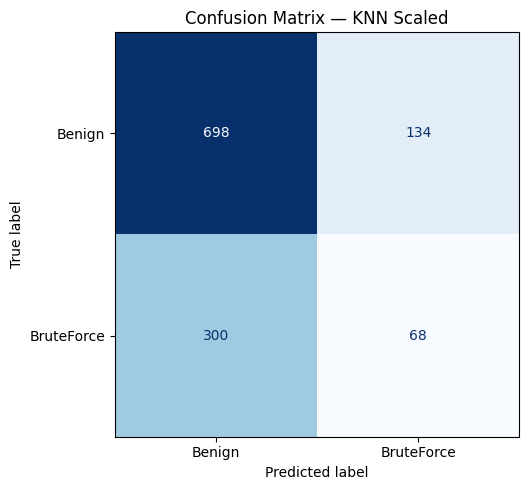

In [ ]:
fig, ax = plt.subplots(figsize=(6, 5))
cm = confusion_matrix(y_test, y_pred_scaled)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le_attack.classes_)
disp.plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title('Confusion Matrix — KNN Scaled')
plt.tight_layout()
plt.show()

---
## Step 5: Second Model — Decision Tree



In [ ]:
dt = DecisionTreeClassifier(random_state=42, max_depth=8, class_weight='balanced')
dt.fit(X_train, y_train)
y_pred_dt = dt.predict(X_test)

print('Decision Tree Results')
print('Accuracy:', round(accuracy_score(y_test, y_pred_dt), 4))
print('Weighted F1:', round(f1_score(y_test, y_pred_dt, average='weighted'), 4))
print(classification_report(y_test, y_pred_dt, target_names=le_attack.classes_))

Decision Tree Results
Accuracy: 0.5842
Weighted F1: 0.5788
              precision    recall  f1-score   support

      Benign       0.69      0.72      0.71       832
  BruteForce       0.31      0.28      0.29       368

    accuracy                           0.58      1200
   macro avg       0.50      0.50      0.50      1200
weighted avg       0.57      0.58      0.58      1200



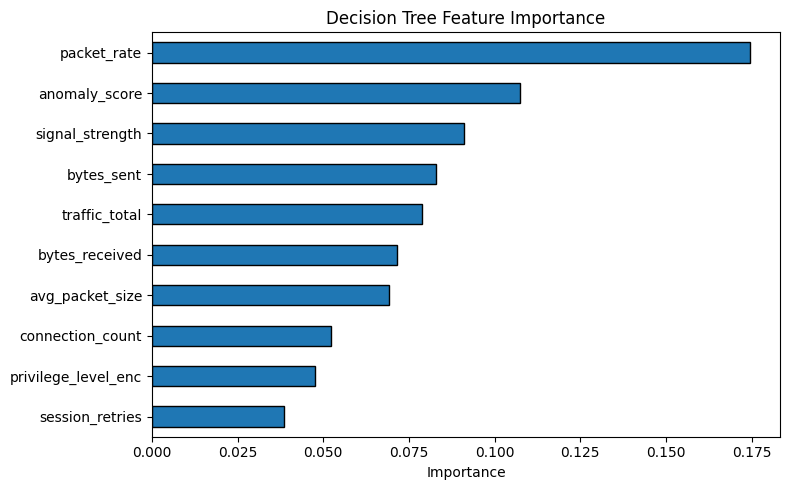

,0
packet_rate,0.174549
anomaly_score,0.107293
signal_strength,0.091068
bytes_sent,0.082942
traffic_total,0.078941
bytes_received,0.071511
avg_packet_size,0.069260
connection_count,0.052333
privilege_level_enc,0.047568
session_retries,0.038409


In [ ]:
feature_importance = pd.Series(dt.feature_importances_, index=FEATURES).sort_values(ascending=False).head(10)
ax = feature_importance.sort_values().plot(kind='barh', figsize=(8,5), edgecolor='black')
ax.set_title('Decision Tree Feature Importance')
ax.set_xlabel('Importance')
plt.tight_layout()
plt.show()
feature_importance

---
## Step 6: Model Comparison

                Model  Accuracy  Weighted F1
       KNN no scaling    0.6100       0.5775
           KNN scaled    0.6383       0.6021
Decision Tree depth 8    0.5842       0.5788


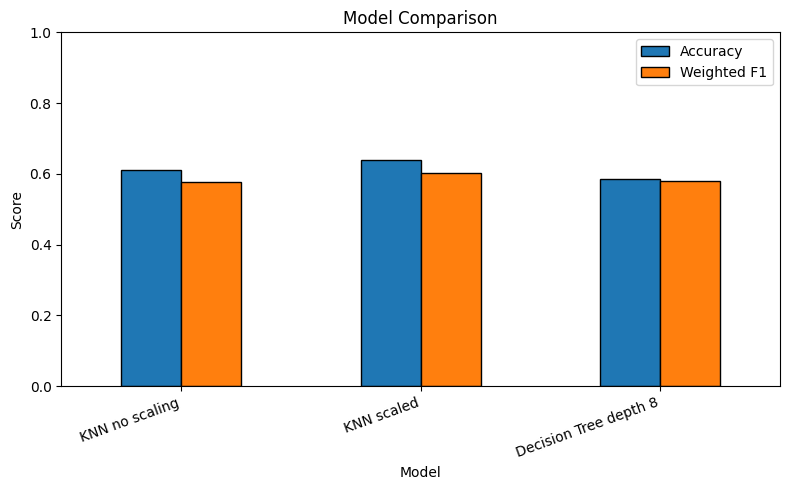

In [ ]:
comparison = pd.DataFrame([
    {'Model': 'KNN no scaling', 'Accuracy': accuracy_score(y_test, y_pred_no_scale), 'Weighted F1': f1_score(y_test, y_pred_no_scale, average='weighted')},
    {'Model': 'KNN scaled', 'Accuracy': accuracy_score(y_test, y_pred_scaled), 'Weighted F1': f1_score(y_test, y_pred_scaled, average='weighted')},
    {'Model': 'Decision Tree depth 8', 'Accuracy': accuracy_score(y_test, y_pred_dt), 'Weighted F1': f1_score(y_test, y_pred_dt, average='weighted')},
])
print(comparison.round(4).to_string(index=False))

ax = comparison.set_index('Model').plot(kind='bar', figsize=(8,5), edgecolor='black')
ax.set_title('Model Comparison')
ax.set_ylim(0,1)
ax.set_ylabel('Score')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()